# MySQL, pandas, and Matplotlib Analysis
Read employees from MySQL, analyze them with pandas, and make charts with Matplotlib. Run cells from top to bottom. Keep your MySQL server running.

## Contents
1. Libraries and Setup
2. Connection Settings
3. Connect to MySQL
4. Inspect the Employees Table
5. Load Data into pandas
6. Inspect and Prepare Data
7. Summarize Data
8. Create Charts
9. Export and Disconnect
10. Practice and Troubleshooting

## 1. Libraries and Setup
PyMySQL connects to MySQL. SQLAlchemy manages the connection. pandas stores query results, and Matplotlib makes charts.

Install missing packages with the command below. `%pip` uses your notebook’s Python environment. Restart the kernel afterward if needed.

```python
%pip install pandas sqlalchemy "pymysql[rsa]" matplotlib
```

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from getpass import getpass
from sqlalchemy import create_engine, URL, text

print('Libraries imported.')

Libraries imported.


## 2. Connection Settings
Use your Workbench settings: host `127.0.0.1`, port `3306`, username `root`, database `employees_python`, and table `employees`. Enter your password at the private prompt. Keep the password out of the notebook code.

In [2]:
db_host = '127.0.0.1'
db_port = 3306
db_name = 'employees_python'
db_table = 'employees'
db_user = 'root'
db_password = getpass('MySQL password: ')

## 3. Connect to MySQL
`URL.create()` builds the connection details, including passwords with special characters. `engine.connect()` opens the connection. Keep your MySQL server running.

In [3]:
connection_url = URL.create(
    drivername='mysql+pymysql',
    username=db_user,
    password=db_password,
    host=db_host,
    port=db_port,
    database=db_name,
)
engine = create_engine(connection_url, pool_pre_ping=True, connect_args={'connect_timeout': 10})
del db_password
del connection_url

with engine.connect() as connection:
    connection.execute(text('SELECT 1'))

print('Connected to MySQL successfully.')

Connected to MySQL successfully.


## 4. Inspect the Employees Table
Check the column names and row count. These queries use the `employees` table. Update the SQL if you rename it.

In [4]:
with engine.connect() as connection:
    columns_df = pd.read_sql(text('SHOW COLUMNS FROM `employees`'), connection)
    row_count_df = pd.read_sql(text('SELECT COUNT(*) AS total_rows FROM `employees`'), connection)

display(columns_df)
display(row_count_df)

,Field,Type,Null,Key,Default,Extra
0,First Name,text,YES,,None,
1,Gender,text,YES,,None,
2,Start Date,text,YES,,None,
3,Last Login Time,text,YES,,None,
4,Salary,int,YES,,None,
5,Bonus %,double,YES,,None,
6,Senior Management,text,YES,,None,
7,Team,text,YES,,None,


,total_rows
0,1000


## 5. Load Data into pandas
`pd.read_sql()` loads SQL results into a DataFrame. Start with ten rows to check the data.

In [5]:
with engine.connect() as connection:
    employees_preview = pd.read_sql(text('SELECT * FROM `employees` LIMIT 10'), connection)

employees_preview

,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,true,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,true,
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,false,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,true,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,true,Client Services
5,Dennis,Male,4/18/1987,1:35 AM,115163,10.125,false,Legal
6,Ruby,Female,8/17/1987,4:20 PM,65476,10.012,true,Product
7,,Female,7/20/2015,10:43 AM,45906,11.598,,Finance
8,Angela,Female,11/22/2005,6:29 AM,95570,18.523,true,Engineering
9,Frances,Female,8/8/2002,6:51 AM,139852,7.524,true,Business Development


### Load an analysis sample
Load up to 10,000 rows for analysis. This is not a random sample, and row order can change. Remove `LIMIT 10000` to load the full table. Charts use only the loaded rows.

In [6]:
with engine.connect() as connection:
    employees_df = pd.read_sql(text('SELECT * FROM `employees` LIMIT 10000'), connection)

print(f'Loaded {len(employees_df):,} rows and {len(employees_df.columns)} columns.')
employees_df.head()

Loaded 1,000 rows and 8 columns.


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,true,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,true,
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,false,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,true,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,true,Client Services


## 6. Inspect and Prepare Data
Check column types, missing values, and duplicate rows. Make a copy before cleaning. Review missing and repeated data before deciding what to remove.

In [7]:
employees_df.info()
quality_summary = pd.DataFrame({
    'dtype': employees_df.dtypes.astype(str),
    'missing_values': employees_df.isna().sum(),
})
display(quality_summary)
print('Duplicate rows:', employees_df.duplicated().sum())
analysis_df = employees_df.copy()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   First Name         1000 non-null   str    
 1   Gender             1000 non-null   str    
 2   Start Date         1000 non-null   str    
 3   Last Login Time    1000 non-null   str    
 4   Salary             1000 non-null   int64  
 5   Bonus %            1000 non-null   float64
 6   Senior Management  1000 non-null   str    
 7   Team               1000 non-null   str    
dtypes: float64(1), int64(1), str(6)
memory usage: 102.0 KB


,dtype,missing_values
First Name,str,0
Gender,str,0
Start Date,str,0
Last Login Time,str,0
Salary,int64,0
Bonus %,float64,0
Senior Management,str,0
Team,str,0


Duplicate rows: 0


### Choose meaningful columns
The examples use `Salary` for numbers and `Team` for groups. Change these names to explore other columns. Avoid using ID numbers as measurements.

If salary is stored as text, use `pd.to_numeric(analysis_df['Salary'], errors='coerce')` and assign the result back to the column. Invalid values become missing.

In [8]:
numeric_columns = analysis_df.select_dtypes(include='number').columns.tolist()
categorical_columns = analysis_df.select_dtypes(include=['object', 'string', 'category', 'bool']).columns.tolist()
print('Numeric columns:', numeric_columns)
print('Categorical candidates:', categorical_columns)

# Salary and Team match the employees table. Change these to explore other columns.
numeric_column = 'Salary'
category_column = 'Team'

Numeric columns: ['Salary', 'Bonus %']
Categorical candidates: ['First Name', 'Gender', 'Start Date', 'Last Login Time', 'Senior Management', 'Team']


## 7. Summarize Data
`describe()` summarizes numeric columns. `groupby()` summarizes each team. `dropna=False` keeps a group for missing team names.

In [9]:
numeric_data = analysis_df.select_dtypes(include='number')
if numeric_data.shape[1] > 0:
    display(numeric_data.describe())
else:
    print('No numeric columns detected. Inspect and convert appropriate measurements first.')

if category_column is not None and numeric_column is not None:
    grouped_summary = analysis_df.groupby(category_column, dropna=False)[numeric_column].agg(['count', 'mean', 'min', 'max'])
    display(grouped_summary)
else:
    print('Choose category_column and numeric_column in section 6 for a grouped summary.')

,Salary,Bonus %
count,1000.000000,1000.000000
mean,90662.181000,10.207555
std,32923.693342,5.528481
min,35013.000000,1.015000
25%,62613.000000,5.401750
50%,90428.000000,9.838500
75%,118740.250000,14.838000
max,149908.000000,19.944000


,count,mean,min,max
Team,,,,
,43,90763.139535,37919,148291
Business Development,101,91866.316832,36844,147417
Client Services,106,88224.424528,35095,147183
Distribution,90,88500.466667,35575,149105
Engineering,92,94269.195652,36946,147362
Finance,102,92219.480392,35381,149908
Human Resources,91,90944.527473,35203,149903
Legal,88,89303.613636,35061,148985
Marketing,98,90435.591837,36643,149456


## 8. Create Charts
The bar chart counts employees by team. The histogram shows how salaries are spread out. Both use the rows loaded in section 5.

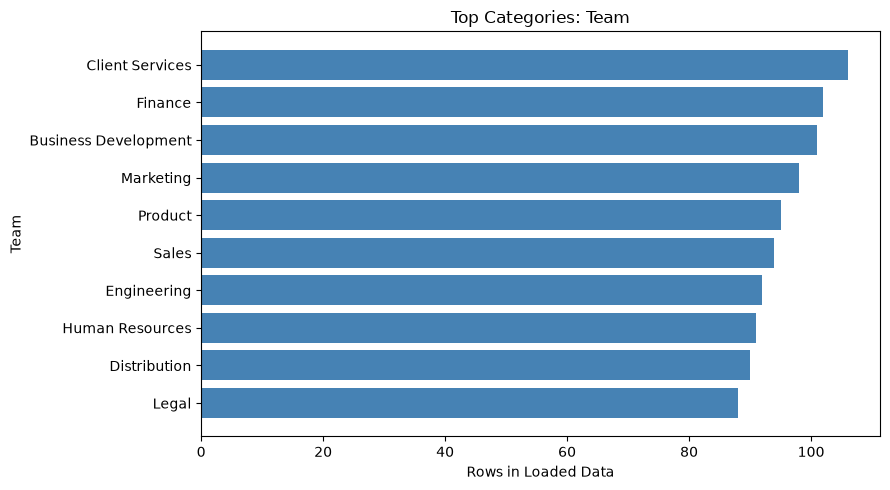

In [10]:
if category_column is not None:
    category_counts = analysis_df[category_column].fillna('(Missing)').astype(str).value_counts().head(10).sort_values()
    if not category_counts.empty:
        fig, ax = plt.subplots(figsize=(9, 5))
        ax.barh(category_counts.index, category_counts.values, color='steelblue')
        ax.set(title=f'Top Categories: {category_column}', xlabel='Rows in Loaded Data', ylabel=category_column)
        fig.tight_layout()
        plt.show()
    else:
        print('No rows available to chart.')
else:
    print('Set category_column in section 6 to create the bar chart.')

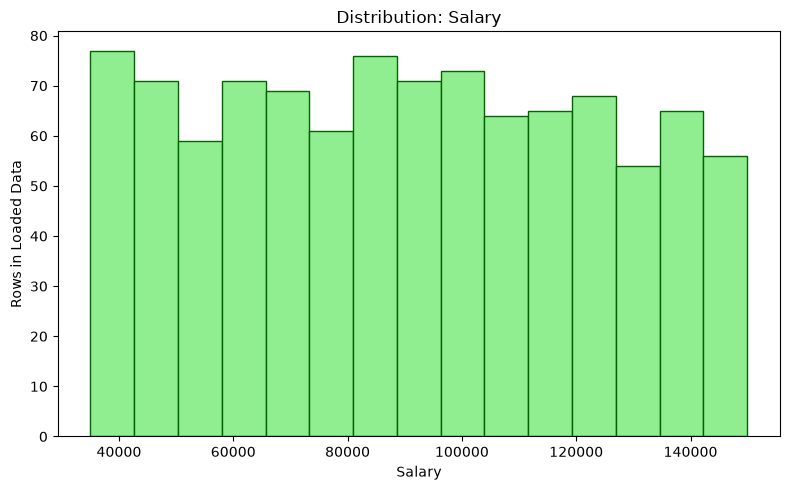

In [11]:
if numeric_column is not None:
    values = pd.to_numeric(analysis_df[numeric_column], errors='coerce').dropna()
    if not values.empty:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.hist(values, bins=15, color='lightgreen', edgecolor='darkgreen')
        ax.set(title=f'Distribution: {numeric_column}', xlabel=numeric_column, ylabel='Rows in Loaded Data')
        fig.tight_layout()
        plt.show()
    else:
        print('No valid numeric values available to chart.')
else:
    print('Set numeric_column in section 6 to create the histogram.')

## 9. Export and Disconnect
Remove `#` from an export line to save a CSV or chart. These exports leave MySQL unchanged. `engine.dispose()` closes the connection pool; rerun section 3 to reconnect.

In [12]:
# analysis_df.to_csv('employees_analysis.csv', index=False)
# fig.savefig('employees_chart.png', dpi=150, bbox_inches='tight')

engine.dispose()
print('Connection pool closed.')

Connection pool closed.


## 10. Practice and Troubleshooting
### Practice
1. Confirm the imported row count matches what you expect.
2. Inspect column types and missing values.
3. Select a meaningful measurement and category in section 6.
4. Compare counts and mean values across categories.
5. Create and optionally export both charts.

### Common connection issues
- **ModuleNotFoundError:** run the installation command in section 1 in this notebook’s environment.
- **Connection refused / cannot connect:** check that the MySQL server is running and the host and port match Workbench.
- **Access denied:** check your MySQL username, password, and permissions.
- **Unknown database / missing table:** verify `employees_python` and `employees` in Workbench.
- **Cryptography required:** install `pymysql[rsa]` as shown in section 1.
- **KeyError when analyzing:** use an exact column name from section 6.
- **No chart appears:** choose the relevant column in section 6, then rerun the chart cell.

After changing credentials or connection settings, rerun sections 2 and 3. If sharing a connection error, remove any credentials from the message.

In [13]:
# Write your practice code here
